In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import plotly as py


print("1. Load Dataset : ")
try:
    data=pd.read_csv('covid-data.csv')
except:
    print("Error While Loading Data !!")

1. Load Dataset : 


In [8]:
print("=== Explore Dataset ===")
print("1. Display First 5 Rows")
print("2. Display Data Shape")
print("3. Display Data Types")
print("4. Display Data Infomation")
print("5. Display Column Names")

try:    
    choice=int(input("Enter Your Choice : "))

    if choice==1:
        print("==== First 5 Rows ====")
        print(data.head())
    elif choice==2:
        print("==== Check Dataset Shape ====")
        print(data.shape)
    elif choice==3:
        print("==== Check Data-Types ====")
        print(data.dtypes)
    elif choice==4:
        print("==== Display Data-Infomation ====")
        data.info()
    elif choice==5:
        print("==== Display Column Names ====")
        print(data.columns)
    else:
        print("Invalid Choice (1-4)")
except :
    print("Error Occured !! Please Check Your Code")

=== Explore Dataset ===
1. Display First 5 Rows
2. Display Data Shape
3. Display Data Types
4. Display Data Infomation
5. Display Column Names
==== First 5 Rows ====
   FIPS Admin2 Province_State Country_Region                 Date       Lat  \
0   NaN    NaN            NaN    Afghanistan  2022-11-14 04:21:09  33.93911   
1   NaN    NaN            NaN        Albania  2022-11-14 04:21:09  41.15330   
2   NaN    NaN            NaN        Algeria  2022-11-14 04:21:09  28.03390   
3   NaN    NaN            NaN        Andorra  2022-11-14 04:21:09  42.50630   
4   NaN    NaN            NaN         Angola  2022-11-14 04:21:09 -11.20270   

       Long_  Confirmed  Deaths  Recovered  Active Combined_Key  \
0  67.709953     204510    7829        NaN     NaN  Afghanistan   
1  20.168300     333156    3593        NaN     NaN      Albania   
2   1.659600     270939    6881        NaN     NaN      Algeria   
3   1.521800      46664     155        NaN     NaN      Andorra   
4  17.873900     103131 

In [9]:
print("==== Data Cleaning ====")
print("1. Handle Missing Values")
print("2. Convert Date Column to DateTime")
print("3. Remove Duplicate Rows")

try:
    choice=int(input("Enter Your Choice : "))

    if choice==1:
        print("==== Handle Missing Values ====")
        print("1. Drop Rows with Missing Values")
        print("2. Fill Missing Values with Mean/Median/Mode")
        choice2=int(input("Enter Your Choice : "))
        if choice2==1:
            print("===== Sum of Missing Values =====")
            print(data.isna().sum())
        elif choice2==2:
            print("===== Drop Rows With Missing Values =====")
            if data.isnull().empty:
                print("No Missing Values in Dataset !!")
            else:
                print("====== Before Cleaning =====")
                print()
                print(data.isna().sum())

                print("====== After Cleaning ======")
                print()
                data=data.dropna()
                print(data.isna().sum())
                print()
                print("Data Cleaned Sucessfullly !!")
        elif choice2==3:
            print("===== Replace Missing Values With Specific Value =====")
            print("1. Replace With 0")
            print("2. Replace With Mean")
            print("3. Replace With Median")
            print("4. Replace With Mode")

            ch1=int(input("Enter Your Choice : "))
            if ch1==1:
                data=data.fillna(0)
                print("Missing Values Replaced With 0 Successfully !!")
            elif ch1==2:
                data=data.fillna(data.mean())
                print("Missing Values Replaced With Mean Successfully !!")
            elif ch1==3:
                data=data.fillna(data.median())
                print("Missing Values Replaced With Median Successfully !!")
            elif ch1==4:
                data=data.fillna(data.mode().iloc[0])
                print("Missing Values Replaced With Mode Successfully !!")
            else:
                print("Invalid Choice (1-4)")
        elif choice==2:
            print("==== Convert Date Column to DateTime ====")
            data['Date']=pd.to_datetime(data['Date'])
            print("Date Column Converted to DateTime Successfully !!")
        elif choice==3:

            print("==== Remove Duplicate Records ====")
            print("1. Check For Duplicate Records")
            print("2. Remove Duplicate Records")

            ch=int(input("Enter Your Choice : "))

            if ch==1:
                print("===== Check For Duplicate Records =====")
                print(data.duplicated().sum())
            elif ch==2:
                print("===== Remove Duplicate Records =====")
                if data.duplicated().sum()==0:
                    print("No Duplicate Records Found !!")
                else:
                    print("====== Before Cleaning =====")
                    print()
                    print(data.duplicated().sum())

                    print("====== After Cleaning ======")
                    print()
                    data=data.drop_duplicates()
                    print(data.duplicated().sum())
                    print()
                    print("Duplicate Records Removed Sucessfully !!")
            else:
                print("Invalid Choice (1-2)")
        else:
            print("Invalid Choice (1-3)")
except:
    print("Error Occured !! Please Check Your Code")



==== Data Cleaning ====
1. Handle Missing Values
2. Convert Date Column to DateTime
3. Remove Duplicate Rows
==== Handle Missing Values ====
1. Drop Rows with Missing Values
2. Fill Missing Values with Mean/Median/Mode
===== Sum of Missing Values =====
FIPS                    748
Admin2                  744
Province_State          179
Country_Region            0
Date                      0
Lat                      91
Long_                    91
Confirmed                 0
Deaths                    0
Recovered              4016
Active                 4016
Combined_Key              0
Incident_Rate            94
Case_Fatality_Ratio      42
dtype: int64


In [10]:
print("=== Data Analysis ===")
print("1. Analysis of COVID-19 Cases Over Time")
print("2. Analysis of Recoveries Over Time")
print("3. Analysis of Deaths Over Time")
print("4. Comparison of Different Countries")
print("5. Country With Highest Cases, Recoveries and Deaths")

try:
    choice=int(input("Enter Your Choice : "))

    if choice==1:
        print("=== Analysis of COVID-19 Cases Over Time ===")
        print(data[['Date','Confirmed']].describe())
    elif choice==2:
        print("=== Analysis of Recoveries Over Time ===")
        print(data[['Date','Recovered']].describe())
    elif choice==3:
        print("=== Analysis of Deaths Over Time ===")
        print(data[['Date','Deaths']].describe())
    elif choice==4:
        print("=== Comparison of Different Countries ===")
        print("1. Compare Confirmed Cases")
        print("2. Compare Recoveries")
        print("3. Compare Deaths")

        ch=int(input("Enter Your Choice : "))
        if ch==1:
            print("=== Compare Confirmed Cases ===")
            country=input("Enter Country Name : ")
            country_data=data[data['Country_Region']==country]
            plt.figure(figsize=(10,5))
            sb.lineplot(x='Date',
                        y='Confirmed',
                        data=country_data)
            plt.title(f'Confirmed Cases in {country} Over Time')
            plt.xlabel('Date')
            plt.ylabel('Confirmed Cases')
            plt.show()
        elif ch==2:
            print("=== Compare Recoveries ===")
            country=input("Enter Country Name : ")
            country_data=data[data['Country_Region']==country]
            plt.figure(figsize=(10,5))
            sb.lineplot(x='Date',
                        y='Recovered',
                        data=country_data)
            plt.title(f'Recoveries in {country} Over Time')
            plt.xlabel('Date')
            plt.ylabel('Recoveries')
            plt.show()
        elif ch==3:
            print("=== Compare Deaths ===")
            country=input("Enter Country Name : ")
            country_data=data[data['Country_Region']==country]
            plt.figure(figsize=(10,5))
            sb.lineplot(x='Date',y='Deaths',data=country_data)
            plt.title(f'Deaths in {country} Over Time')
            plt.xlabel('Date')
            plt.ylabel('Deaths')
            plt.show()
        else:
             print("Invalid Choice (1-3)")
    elif choice==5:
        print("=== Country With Highest Cases, Recoveries and Deaths ===")
        print("1. Country With Highest Confirmed Cases")
        print("2. Country With Highest Recoveries")
        print("3. Country With Highest Deaths")

        ch=int(input("Enter Your Choice : "))
        if ch==1:
            print("=== Country With Highest Confirmed Cases ===")
            country=data.groupby('Country_Region')['Confirmed'].sum().idxmax()
            cases=data.groupby('Country_Region')['Confirmed'].sum().max()
            print(f'Country With Highest Confirmed Cases : {country} ({cases})')
        elif ch==2:
            print("=== Country With Highest Recoveries ===")
            country=data.groupby('Country_Region')['Recovered'].sum().idxmax()
            recoveries=data.groupby('Country_Region')['Recovered'].sum().max()
            print(f'Country With Highest Recoveries : {country} ({recoveries})')
        elif ch==3:
            print("=== Country With Highest Deaths ===")
            country=data.groupby('Country_Region')['Deaths'].sum().idxmax()
            deaths=data.groupby('Country_Region')['Deaths'].sum().max()
            print(f'Country With Highest Deaths : {country} ({deaths})')
        else:
             print("Invalid Choice (1-3)")

        

except:
    print("Error Occured !! Please Check Your Code")

=== Data Analysis ===
1. Analysis of COVID-19 Cases Over Time
2. Analysis of Recoveries Over Time
3. Analysis of Deaths Over Time
4. Comparison of Different Countries
5. Country With Highest Cases, Recoveries and Deaths
=== Analysis of COVID-19 Cases Over Time ===
          Confirmed
count  4.016000e+03
mean   1.582410e+05
std    9.950324e+05
min    0.000000e+00
25%    3.566250e+03
50%    1.016350e+04
75%    4.442825e+04
max    3.608012e+07


=== Data Visualization ===
1. Line Chart : Cases Over Time
2. Line Chart : Recoveries Over Time
3. Line Chart : Deaths Over Time
4. Bar Chart : Cases by Country
5. Compare Government Interventions with Virus Spread
=== Line Chart : Cases Over Time ===


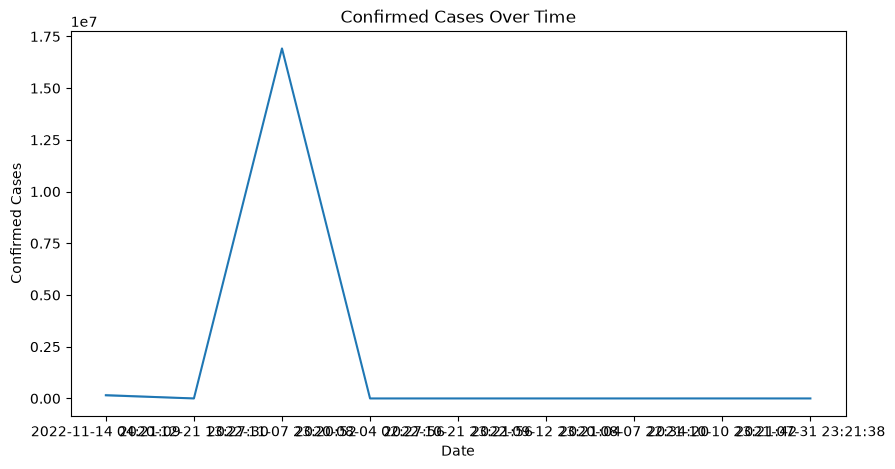

In [11]:
print("=== Data Visualization ===")
print("1. Line Chart : Cases Over Time")
print("2. Line Chart : Recoveries Over Time")
print("3. Line Chart : Deaths Over Time")
print("4. Bar Chart : Cases by Country")
print("5. Compare Government Interventions with Virus Spread")

try:
    choice=int(input("Enter Your Choice : "))
    if choice==1:
        print("=== Line Chart : Cases Over Time ===")
        plt.figure(figsize=(10,5))
        sb.lineplot(x='Date',
                    y='Confirmed',
                    data=data)
        plt.title('Confirmed Cases Over Time')
        plt.xlabel('Date')
        plt.ylabel('Confirmed Cases')
        plt.show()
    elif choice==2:
        print("=== Line Chart : Recoveries Over Time ===")
        plt.figure(figsize=(10,5))
        sb.lineplot(x='Date',
                    y='Recovered',
                    data=data)
        plt.title('Recoveries Over Time')
        plt.xlabel('Date')
        plt.ylabel('Recoveries')
        plt.show()
    elif choice ==3:
        print("=== Line Chart : Deaths Over Time ===")
        plt.figure(figsize=(10,5))
        sb.lineplot(x='Date',
                    y='Deaths',
                    data=data)
        plt.title('Deaths Over Time')
        plt.xlabel('Date')
        plt.ylabel('Deaths')
        plt.show()
    elif choice==4:
        print("=== Bar Chart : Cases by Country ===")
        country_cases=data.groupby('Country_Region')['Confirmed'].sum().sort_values(ascending=False).head(10)
        plt.figure(figsize=(10,5))
        sb.barplot(x=country_cases.index,
                    y=country_cases.values)
        plt.title('Top 10 Countries with Highest Confirmed Cases')
        plt.xlabel('Country')
        plt.ylabel('Confirmed Cases')
        plt.xticks(rotation=45)
        plt.show()

    elif choice==5:
        print("=== Compare Government Interventions with Virus Spread ===")
        interventions_data=pd.read_csv('government_interventions.csv')
        merged_data=pd.merge(data,interventions_data,on=['Country_Region','Date'])
        plt.figure(figsize=(10,5))
        sb.lineplot(x='Date',
                    y='Confirmed',
                    hue='Intervention',
                    data=merged_data)
        plt.title('Compare Government Interventions with Virus Spread')
        plt.xlabel('Date')
        plt.ylabel('Confirmed Cases')
        plt.xticks(rotation=45)
        plt.show()

    else:
        print("Invalid Choice (1-5)")
except:
    print("Error Occured !! Please Check Your Code")


In [12]:
print("Interactive Visualization")
print("Interactive Charts using plotly")
print("1. Line Chart : Cases Over Time")
print("2. Line Chart : Recoveries Over Time")
print("3. Line Chart : Deaths Over Time")
print("4. Bar Chart : Cases by Country")

# try:

choice=int(input("Enter Your Choice : "))
if choice==1:
    print("=== Line Chart : Cases Over Time ===")
    fig=py.graph_objects.Figure()
    fig.add_trace(py.graph_objects.Scatter(x=data['Date'],
                                            y=data['Confirmed'],
                                            mode='lines',
                                            name='Confirmed'))
    fig.update_layout(title='Confirmed Cases Over Time',
                    xaxis_title='Date',
                    yaxis_title='Confirmed Cases')
    fig.show()
elif choice==2:
    print("=== Line Chart : Recoveries Over Time ===")
    fig=py.graph_objects.Figure()
    fig.add_trace(py.graph_objects.Scatter(x=data['Date'],
                                            y=data['Recovered'],
                                            mode='lines',
                                            name='Recovered'))
    fig.update_layout(title='Recoveries Over Time',
                    xaxis_title='Date',
                    yaxis_title='Recoveries')
    fig.show()
elif choice==3:
    print("=== Line Chart : Deaths Over Time ===")
    fig=py.graph_objects.Figure()
    fig.add_trace(py.graph_objects.Scatter(x=data['Date'],
                                            y=data['Deaths'],
                                            mode='lines',
                                            name='Deaths'))
    fig.update_layout(title='Deaths Over Time',
                    xaxis_title='Date',
                    yaxis_title='Deaths')
    fig.show()
elif choice==4:
    print("=== Bar Chart : Cases by Country ===")
    country_cases=data.groupby('Country_Region')['Confirmed'].sum().sort_values(ascending=False).head(10)
    fig=py.graph_objects.Figure()
    fig.add_trace(py.graph_objects.Bar(x=country_cases.index,
                                        y=country_cases.values,
                                        name='Confirmed Cases'))
    fig.update_layout(title='Top 10 Countries with Highest Confirmed Cases',
                    xaxis_title='Country',
                    yaxis_title='Confirmed Cases')

    fig.show()
else:
    print("Invalid Choice (1-4)")
# except:
#     print("Error Occured !! Please Check Your Code")

Interactive Visualization
Interactive Charts using plotly
1. Line Chart : Cases Over Time
2. Line Chart : Recoveries Over Time
3. Line Chart : Deaths Over Time
4. Bar Chart : Cases by Country
=== Line Chart : Recoveries Over Time ===


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed